# UBOS District Population and Classroom Demand

This notebook uses the reusable population and forecasting classes in [`src/ubos.py`](src/ubos.py) to explore district population trends and estimate additional classroom demand. The notebook is deliberately organized as short, ordered steps so each calculation and its interpretation can be reviewed separately.

## Questions and assumptions

We will summarize the supplied 2015–2024 population observations, compare three forecasting approaches using a holdout period, forecast five years beyond 2024, and estimate net new classrooms by 2029.

Population values are in thousands. The district figures are illustrative inputs. The classroom estimate assumes 18% of net additional population is school-age, 53 pupils per classroom, and that current (2024) demand is already served. It is a simplified planning estimate, not an official UBOS or Ministry projection.

In [4]:
from math import ceil
import statistics

import matplotlib.pyplot as plt
import numpy as np

from src.ubos import (
    CAGRForecaster,
    DistrictPopulation,
    FibonacciRatioForecaster,
    Forecaster,
    LinearTrendForecaster,
)

## 1. Set the analysis period and data

The 2015–2021 observations are used to fit each model; 2022–2024 are reserved for out-of-sample comparison. After selecting a model, we refit it to all available observations before producing the 2025–2029 forecast.

In [5]:
YEARS = np.arange(2015, 2025)
TRAIN_END_YEAR = 2021
FORECAST_HORIZON = 5
BOOTSTRAP_RESAMPLES = 1_000

DISTRICT_DATA = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso": [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu": [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    "Mbarara": [465, 480, 498, 517, 538, 560, 584, 609, 636, 664],
    "Jinja": [471, 482, 494, 507, 521, 536, 552, 569, 587, 606],
}

MODEL_TYPES: dict[str, type[Forecaster]] = {
    "Linear trend": LinearTrendForecaster,
    "CAGR": CAGRForecaster,
    "Fibonacci ratio": FibonacciRatioForecaster,
}

districts = {
    name: DistrictPopulation(name, YEARS, np.asarray(values, dtype=float))
    for name, values in DISTRICT_DATA.items()
}
train_mask = YEARS <= TRAIN_END_YEAR
test_mask = YEARS > TRAIN_END_YEAR
forecast_years = np.arange(YEARS[-1] + 1, YEARS[-1] + FORECAST_HORIZON + 1)

print(f"Districts: {', '.join(districts)}")
print(f"Training years: {YEARS[train_mask][0]}–{YEARS[train_mask][-1]}")
print(f"Holdout years: {YEARS[test_mask][0]}–{YEARS[test_mask][-1]}")
print(f"Forecast years: {forecast_years[0]}–{forecast_years[-1]}")

Districts: Kampala, Wakiso, Gulu, Mbarara, Jinja
Training years: 2015–2021
Holdout years: 2022–2024
Forecast years: 2025–2029


## 2. Inspect the population observations

`DistrictPopulation` validates and stores one district's year and population arrays. The quick check below confirms the observation count and endpoints before calculating statistics.

In [6]:
for district in districts.values():
    print(
        f"{district.name:10} | {len(district):2} annual observations | "
        f"{district.years[0]:.0f}: {district.population[0]:.0f}k | "
        f"{district.years[-1]:.0f}: {district.population[-1]:.0f}k"
    )

Kampala    | 10 annual observations | 2015: 1200k | 2024: 1800k
Wakiso     | 10 annual observations | 2015: 950k | 2024: 1670k
Gulu       | 10 annual observations | 2015: 320k | 2024: 480k
Mbarara    | 10 annual observations | 2015: 465k | 2024: 664k
Jinja      | 10 annual observations | 2015: 471k | 2024: 606k


## 3. Descriptive statistics

The statistics module reports sample variance and standard deviation (denominator *n − 1*). NumPy's default uses population variance and standard deviation (denominator *n*). Showing both makes the difference explicit; these measures describe the supplied historical series, not uncertainty in future population.

In [7]:
for district in districts.values():
    population = district.population
    print(f"\n{district.name} (thousands)")
    print(
        f"  Mean: {statistics.mean(population):.2f} | "
        f"Median: {statistics.median(population):.2f}"
    )
    print(
        f"  Sample variance / stdev: {statistics.variance(population):.2f} / "
        f"{statistics.stdev(population):.2f}"
    )
    print(
        f"  Population variance / stdev (NumPy ddof=0): "
        f"{np.var(population):.2f} / {np.std(population):.2f}"
    )
    print(
        f"  Sample variance / stdev (NumPy ddof=1): "
        f"{np.var(population, ddof=1):.2f} / {np.std(population, ddof=1):.2f}"
    )


Kampala (thousands)
  Mean: 1477.00 | Median: 1460.00
  Sample variance / stdev: 42601.11 / 206.40
  Population variance / stdev (NumPy ddof=0): 38341.00 / 195.81
  Sample variance / stdev (NumPy ddof=1): 42601.11 / 206.40

Wakiso (thousands)
  Mean: 1280.00 | Median: 1260.00
  Sample variance / stdev: 60066.67 / 245.09
  Population variance / stdev (NumPy ddof=0): 54060.00 / 232.51
  Sample variance / stdev (NumPy ddof=1): 60066.67 / 245.09

Gulu (thousands)
  Mean: 389.50 | Median: 382.50
  Sample variance / stdev: 2885.83 / 53.72
  Population variance / stdev (NumPy ddof=0): 2597.25 / 50.96
  Sample variance / stdev (NumPy ddof=1): 2885.83 / 53.72

Mbarara (thousands)
  Mean: 555.10 | Median: 549.00
  Sample variance / stdev: 4547.88 / 67.44
  Population variance / stdev (NumPy ddof=0): 4093.09 / 63.98
  Sample variance / stdev (NumPy ddof=1): 4547.88 / 67.44

Jinja (thousands)
  Mean: 532.50 | Median: 528.50
  Sample variance / stdev: 2077.17 / 45.58
  Population variance / stdev 

## 4. Annual growth and full-period CAGR

Year-on-year (YoY) growth is the change from one year to the next divided by the previous year's population. Compound annual growth rate (CAGR) summarizes the annualized change from the first to last observation; it does not imply that growth was identical in every intervening year.

In [8]:
growth_results = {}
for district in districts.values():
    yoy = np.diff(district.population) / district.population[:-1] * 100
    elapsed = district.years[-1] - district.years[0]
    cagr = (district.population[-1] / district.population[0]) ** (1 / elapsed) - 1
    growth_results[district.name] = {"yoy_percent": yoy, "cagr_percent": cagr * 100}
    print(f"\n{district.name} YoY growth (%): {np.round(yoy, 2).tolist()}")
    print(f"{district.name} CAGR, {district.years[0]:.0f}–{district.years[-1]:.0f}: {cagr * 100:.2f}%")


Kampala YoY growth (%): [4.17, 4.0, 3.85, 5.19, 5.63, 5.33, 4.43, 4.24, 4.65]
Kampala CAGR, 2015–2024: 4.61%

Wakiso YoY growth (%): [5.26, 7.0, 7.48, 6.09, 6.56, 6.92, 6.47, 6.08, 6.37]
Wakiso CAGR, 2015–2024: 6.47%

Gulu YoY growth (%): [3.12, 4.55, 4.35, 4.17, 4.0, 5.13, 4.88, 5.81, 5.49]
Gulu CAGR, 2015–2024: 4.61%

Mbarara YoY growth (%): [3.23, 3.75, 3.82, 4.06, 4.09, 4.29, 4.28, 4.43, 4.4]
Mbarara CAGR, 2015–2024: 4.04%

Jinja YoY growth (%): [2.34, 2.49, 2.63, 2.76, 2.88, 2.99, 3.08, 3.16, 3.24]
Jinja CAGR, 2015–2024: 2.84%


## 5. Compare forecasting models on the holdout years

Each model is fitted only on 2015–2021, then predicts 2022–2024. MAE and RMSE are in thousands of people; lower values indicate smaller errors. MAPE is a percentage error and is useful for comparing districts of different sizes. The model with the lowest holdout RMSE is selected separately for each district.

The Fibonacci-ratio forecaster is retained as a mathematical comparison only. Its ratios approach the golden ratio, causing implausibly rapid growth for ordinary demographic projections.

In [9]:
def calculate_metrics(actual: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    errors = actual - predicted
    nonzero_actual = actual != 0
    if not np.any(nonzero_actual):
        raise ValueError("MAPE is undefined when every actual value is zero.")
    return {
        "MAE": float(np.mean(np.abs(errors))),
        "RMSE": float(np.sqrt(np.mean(errors**2))),
        "MAPE": float(np.mean(np.abs(errors[nonzero_actual] / actual[nonzero_actual])) * 100),
    }


holdout_results = {}
selected_models = {}
for name, district in districts.items():
    results = {}
    for model_name, model_type in MODEL_TYPES.items():
        model = model_type().fit(
            district.years[train_mask], district.population[train_mask]
        )
        predicted = model.predict(int(np.sum(test_mask)))
        results[model_name] = calculate_metrics(
            district.population[test_mask], predicted
        )
    holdout_results[name] = results
    selected_models[name] = min(results, key=lambda model: results[model]["RMSE"])

    print(f"\n{name} holdout results (2022–2024)")
    print(f"{'Model':20} {'MAE':>10} {'RMSE':>10} {'MAPE':>10}")
    for model_name, metrics in results.items():
        print(
            f"{model_name:20} {metrics['MAE']:10.2f} "
            f"{metrics['RMSE']:10.2f} {metrics['MAPE']:9.2f}%"
        )
    print(f"Selected by lowest RMSE: {selected_models[name]}")


Kampala holdout results (2022–2024)
Model                       MAE       RMSE       MAPE
Linear trend              37.62      38.97      2.17%
CAGR                       9.62      10.39      0.55%
Fibonacci ratio         1483.33    1890.51     83.77%
Selected by lowest RMSE: CAGR

Wakiso holdout results (2022–2024)
Model                       MAE       RMSE       MAPE
Linear trend              49.40      52.37      3.09%
CAGR                       6.80       8.05      0.42%
Fibonacci ratio         1266.67    1604.39     77.62%
Selected by lowest RMSE: CAGR

Gulu holdout results (2022–2024)
Model                       MAE       RMSE       MAPE
Linear trend              18.57      20.29      4.01%
CAGR                       9.44      10.87      2.02%
Fibonacci ratio          378.33     481.71     80.37%
Selected by lowest RMSE: CAGR

Mbarara holdout results (2022–2024)
Model                       MAE       RMSE       MAPE
Linear trend              16.58      17.71      2.57%
CAGR      

### Reading the model comparison

Holdout performance is a comparison on only three years, so the selected model is not guaranteed to remain the most accurate in the future. RMSE penalizes large misses more heavily than MAE. MAPE can be difficult to interpret when actual values are close to zero; all supplied population values are positive. The Fibonacci model's poor demographic plausibility is a reason not to treat a numerical model selection as automatic policy guidance.

## 6. Refit selected models and forecast 2025–2029

The selected model for each district is refitted using all observations through 2024. The interval is generated by resampling centered fitted residuals independently. It represents variation under this simple residual-bootstrap procedure; it does not capture structural changes, migration shocks, policy changes, or uncertainty in the assumptions.

In [10]:
def bootstrap_prediction_interval(
    model_type: type[Forecaster],
    years: np.ndarray,
    population: np.ndarray,
    horizon: int,
    resamples: int = BOOTSTRAP_RESAMPLES,
    seed: int = 42,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    if resamples < 1_000:
        raise ValueError("At least 1,000 bootstrap resamples are required.")
    model = model_type().fit(years, population)
    forecast = model.predict(horizon)
    residuals = np.asarray(population, dtype=float) - model.fitted_values()
    residuals -= np.mean(residuals)
    rng = np.random.default_rng(seed)
    simulated = forecast + rng.choice(
        residuals, size=(resamples, horizon), replace=True
    )
    lower, upper = np.percentile(simulated, [2.5, 97.5], axis=0)
    return forecast, lower, upper


final_forecasts = {}
for name, district in districts.items():
    model_type = MODEL_TYPES[selected_models[name]]
    forecast, lower, upper = bootstrap_prediction_interval(
        model_type,
        district.years,
        district.population,
        FORECAST_HORIZON,
        seed=42 + len(name),
    )
    final_forecasts[name] = {
        "forecast": forecast,
        "lower": lower,
        "upper": upper,
        "model": selected_models[name],
    }
    print(f"\n{name} — {selected_models[name]} (thousands)")
    for year, value, low, high in zip(forecast_years, forecast, lower, upper):
        print(f"  {year}: {value:.2f} (95% bootstrap interval: {low:.2f}–{high:.2f})")


Kampala — CAGR (thousands)
  2025: 1882.95 (95% bootstrap interval: 1864.32–1895.53)
  2026: 1969.72 (95% bootstrap interval: 1951.09–1982.30)
  2027: 2060.49 (95% bootstrap interval: 2041.86–2073.07)
  2028: 2155.44 (95% bootstrap interval: 2136.81–2168.02)
  2029: 2254.76 (95% bootstrap interval: 2236.14–2267.35)

Wakiso — CAGR (thousands)
  2025: 1778.03 (95% bootstrap interval: 1766.65–1784.86)
  2026: 1893.04 (95% bootstrap interval: 1881.66–1899.87)
  2027: 2015.49 (95% bootstrap interval: 2004.11–2022.32)
  2028: 2145.86 (95% bootstrap interval: 2134.49–2152.70)
  2029: 2284.67 (95% bootstrap interval: 2273.29–2291.50)

Gulu — CAGR (thousands)
  2025: 502.12 (95% bootstrap interval: 496.98–507.83)
  2026: 525.26 (95% bootstrap interval: 520.12–530.97)
  2027: 549.46 (95% bootstrap interval: 544.32–555.17)
  2028: 574.78 (95% bootstrap interval: 569.64–580.49)
  2029: 601.27 (95% bootstrap interval: 596.13–606.98)

Mbarara — CAGR (thousands)
  2025: 690.81 (95% bootstrap interva

## 7. Estimate additional classrooms

For each district, the calculation compares projected 2029 population with 2024 population. Because population is expressed in thousands, the difference is multiplied by 1,000, then by the assumed 18% school-age share. The result is divided by 53 pupils per classroom and rounded up. Negative net population change yields zero additional classrooms under this calculation; replacement needs and existing classroom shortages are not included.

In [11]:
classroom_results = {}
for name, district in districts.items():
    forecast_2029 = final_forecasts[name]["forecast"][-1]
    net_population = forecast_2029 - district.population[-1]
    school_age_population = max(0, net_population * 1_000 * 0.18)
    additional_classrooms = ceil(school_age_population / 53)
    classroom_results[name] = {
        "model": selected_models[name],
        "population_2024_thousands": district.population[-1],
        "population_2029_thousands": forecast_2029,
        "net_change_thousands": net_population,
        "additional_classrooms": additional_classrooms,
    }

print(
    f"{'District':12} {'Selected model':20} {'2024 (k)':>10} "
    f"{'2029 (k)':>10} {'Net change (k)':>15} {'New classrooms':>16}"
)
for name, result in classroom_results.items():
    print(
        f"{name:12} {result['model']:20} "
        f"{result['population_2024_thousands']:10.2f} "
        f"{result['population_2029_thousands']:10.2f} "
        f"{result['net_change_thousands']:15.2f} "
        f"{result['additional_classrooms']:16,d}"
    )

total_additional_classrooms = sum(
    result["additional_classrooms"] for result in classroom_results.values()
)
print(f"\nCombined classroom estimate: {total_additional_classrooms:,}")

District     Selected model         2024 (k)   2029 (k)  Net change (k)   New classrooms
Kampala      CAGR                    1800.00    2254.76          454.76            1,545
Wakiso       CAGR                    1670.00    2284.67          614.67            2,088
Gulu         CAGR                     480.00     601.27          121.27              412
Mbarara      CAGR                     664.00     809.32          145.32              494
Jinja        CAGR                     606.00     697.07           91.07              310

Combined classroom estimate: 4,849


## 8. Visualize historical observations and forecasts

Each panel shows the historical observations, the selected model's fitted values, the 2025–2029 forecast and its bootstrap interval. The vertical marker separates training data from the holdout period used for model selection. Different panels have their own vertical scales.

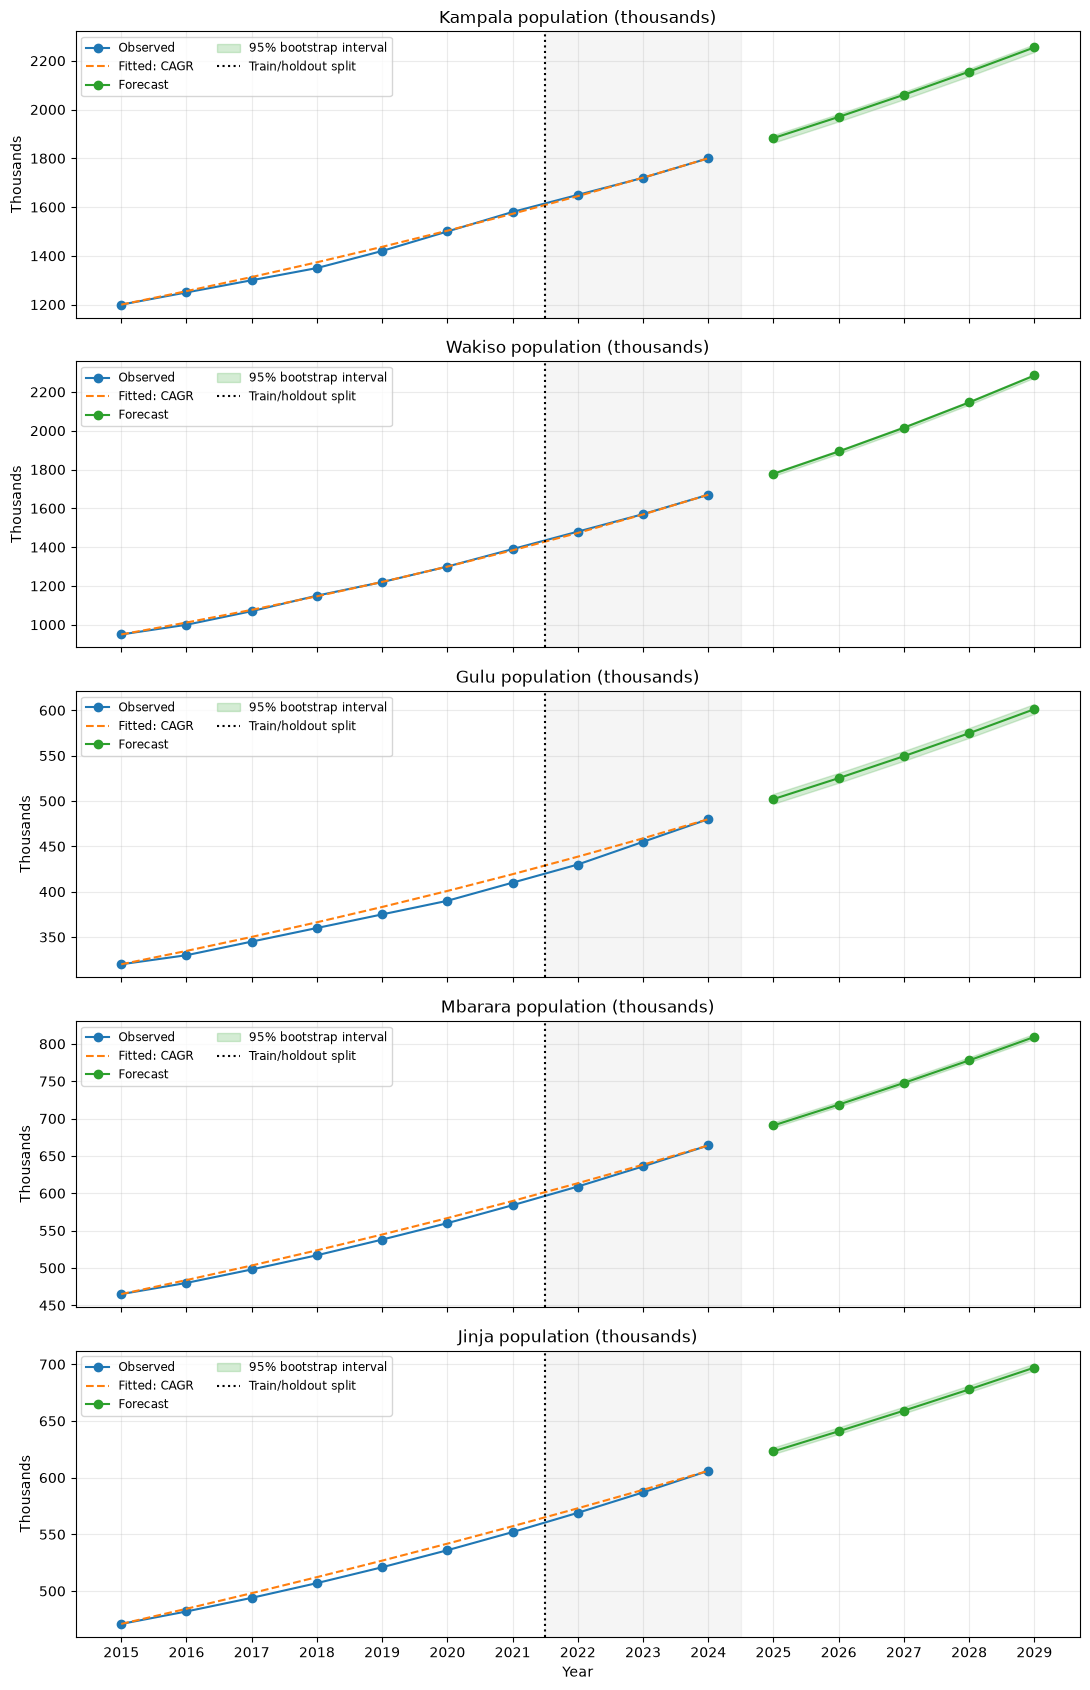

In [12]:
figure, axes = plt.subplots(
    len(districts), 1, figsize=(11, 3.4 * len(districts)), sharex=True
)
for axis, (name, district) in zip(axes, districts.items()):
    result = final_forecasts[name]
    model_type = MODEL_TYPES[result["model"]]
    fitted_model = model_type().fit(district.years, district.population)
    axis.plot(district.years, district.population, "o-", label="Observed", color="tab:blue")
    axis.plot(
        district.years,
        fitted_model.fitted_values(),
        "--",
        label=f"Fitted: {result['model']}",
        color="tab:orange",
    )
    axis.plot(forecast_years, result["forecast"], "o-", label="Forecast", color="tab:green")
    axis.fill_between(
        forecast_years,
        result["lower"],
        result["upper"],
        color="tab:green",
        alpha=0.2,
        label="95% bootstrap interval",
    )
    axis.axvline(TRAIN_END_YEAR + 0.5, color="black", linestyle=":", label="Train/holdout split")
    axis.axvspan(TRAIN_END_YEAR + 0.5, YEARS[-1] + 0.5, color="gray", alpha=0.08)
    axis.set_title(f"{name} population (thousands)")
    axis.set_ylabel("Thousands")
    axis.grid(alpha=0.25)
    axis.legend(loc="best", fontsize="small", ncol=2)

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(np.arange(YEARS[0], forecast_years[-1] + 1))
figure.tight_layout()
plt.show()

## Conclusions

- The district observations show upward population trends over the supplied period, but historical growth rates are not a guarantee of future growth.
- Holdout RMSE provides a consistent, small-sample basis for choosing a forecasting model per district. Results should be revisited when newer or more authoritative data become available.
- The 2025–2029 intervals quantify only resampled historical model residuals. They are not comprehensive confidence bounds for demographic uncertainty.
- The classroom figures are conditional planning estimates driven by the selected model and the stated 18% and 53-pupil assumptions. They do not account for existing shortages, classroom condition, enrollment rates, teacher availability, or geographic distribution.
- The Fibonacci-ratio model is included to compare methods, not as a plausible demographic planning model.

Use the district-level results above alongside official population projections, enrollment data and local capacity assessments before making resource-allocation decisions.